# 10 — Modelo explicativo del precio por m²

**Pregunta:** ¿cuánto del precio por m² se asocia con el estado de la propiedad y con cada característica, una vez que se controla por barrio, tamaño, antigüedad y las demás características? ¿Predice mejor que el benchmark jerárquico?

**Por qué este análisis.** El notebook 04 compara el USD/m² de las propiedades que necesitan obra con el de las recicladas, pero esa comparación no separa el efecto del estado del de la ubicación, la antigüedad o las amenities. Una regresión múltiple aísla cada factor y permite medir el descuento por obra y los premios por amenity en una misma escala.

**Entrada:** `data/processed/remax_deptos_features.csv`.
**Dependencias:** `src/modelos.py` (preparación, ajuste y validación).

**Cómo se interpreta.** La variable respuesta es el logaritmo del USD/m² homogeneizado. El efecto de cada variable se expresa como diferencia porcentual del USD/m², a igualdad de las demás. Son asociaciones y no relaciones causales: el estado, por ejemplo, solo se informa en el 36 % de los avisos.

In [1]:
# 1. ENTORNO, IMPORTS Y CARGA

import os
import sys
from pathlib import Path

# Trabajar sobre la copia local del repositorio: se ubica la raíz (la carpeta
# que contiene src/) y se ejecuta desde ahí. No se clona ni se actualiza nada.
RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import BASE_FEATURES
from src.modelos import (CARACTERISTICAS, FORMULA, preparar_base_modelo, ajustar_hedonico,
                         tabla_efectos, validar_fuera_de_muestra, efecto_necesita_obra,
                         diferencia_obra_vs_reciclada, vif_por_termino, diagnostico_residuos)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv(BASE_FEATURES)
print("Base analítica:", df.shape)

Base analítica: (9499, 100)


## 2. Especificación

Se estima, por mínimos cuadrados, el logaritmo del USD/m² homogeneizado en función de:

- **Ubicación:** barrio oficial (efectos fijos).
- **Tamaño:** grupo de ambientes y logaritmo de la superficie homogeneizada.
- **Antigüedad:** bandas (hasta 10, 11 a 30, 31 a 50, más de 50 años y sin dato).
- **Estado:** `Buen_estado` (referencia), `Reciclada_refaccionada`, `Necesita_obra` y `Sin_clasificar`, más la marca de reciclado parcial.
- **Características del aviso:** 19 indicadores (amenities del edificio, cochera, balcón, vista, luminosidad, etc.).

Se excluyen los avisos marcados como valores extremos o con ambientes dudosos. Los errores estándar son robustos (HC3), porque la varianza del error no es constante.

In [2]:
# 2.1 BASE DEL MODELO

d = preparar_base_modelo(df)
print(f"Avisos en el modelo: {len(d):,} de {len(df):,}")
print("\nEstado de los avisos del modelo:")
display(d["Estado"].value_counts().to_frame("Avisos"))

Avisos en el modelo: 9,232 de 9,499

Estado de los avisos del modelo:


,Avisos
Estado,
Sin_clasificar,5858
Buen_estado,2004
Reciclada_refaccionada,953
Necesita_obra,417


In [3]:
# 2.2 AJUSTE

modelo = ajustar_hedonico(d)
print(f"R² = {modelo.rsquared:.3f}   R² ajustado = {modelo.rsquared_adj:.3f}   N = {int(modelo.nobs):,}")

R² = 0.712   R² ajustado = 0.709   N = 9,232


## 3. Resultados: el estado de la propiedad

**Pregunta:** ¿cuánto menor es el USD/m² de una unidad que necesita obra, a igualdad de barrio, tamaño, antigüedad y características?

In [4]:
# 3.1 EFECTO DEL ESTADO

efectos = tabla_efectos(modelo)
estado = efectos[efectos.index.str.startswith("Estado")]
display(estado)

dif, lo, hi = diferencia_obra_vs_reciclada(modelo)
print(f"\nNecesita_obra frente a Reciclada_refaccionada: {dif:.1f} % (IC 95 %: {lo:.1f} % a {hi:.1f} %)")

,Efecto (%),IC95 inf.,IC95 sup.,p-valor
Variable,,,,
Estado: Reciclada_refaccionada,9.80,8.20,11.43,0.00
Estado: Necesita_obra,-14.35,-16.20,-12.47,0.00
Estado: Sin_clasificar,-0.45,-1.40,0.51,0.36



Necesita_obra frente a Reciclada_refaccionada: -22.0 % (IC 95 %: -23.8 % a -20.1 %)


In [5]:
# 3.2 ROBUSTEZ DEL EFECTO DE NECESITA_OBRA

import src.modelos as modelos

variantes = {
    "Modelo base": d,
    "Sin avisos con señales contradictorias": d[~d["Flag_Senal_Contradictoria"]],
    "Solo avisos con estado informado": d[d["Estado_Propiedad"] != "Sin_clasificar"],
}
filas = {nombre: efecto_necesita_obra(base) for nombre, base in variantes.items()}
filas["Comuna en lugar de barrio"] = efecto_necesita_obra(d, modelos.FORMULA.replace("C(Barrio_Oficial)", "C(Comuna)"))
filas["Sin controlar por antigüedad"] = efecto_necesita_obra(
    d, modelos.FORMULA.replace(" + C(Banda_Antiguedad, Treatment('11_30'))", ""))
robustez = pd.DataFrame(filas).T
robustez["N"] = robustez["N"].astype(int)
display(robustez)

,N,Efecto (%),IC95 inf.,IC95 sup.
Modelo base,9232,-14.35,-16.20,-12.47
Sin avisos con señales contradictorias,9159,-13.43,-15.35,-11.47
Solo avisos con estado informado,3374,-14.36,-16.19,-12.49
Comuna en lugar de barrio,9232,-13.63,-15.70,-11.51
Sin controlar por antigüedad,9232,-16.45,-18.23,-14.62


**Conclusión parcial (estado).** A igualdad de barrio, tamaño, antigüedad y características, una unidad que necesita obra se publica con un USD/m² aproximadamente 14 % menor que una en buen estado, y 22 % menor que una reciclada. Los intervalos son angostos y el efecto se mantiene entre 13 % y 16 % si se excluyen los avisos contradictorios, si se usa solo el estado informado o si se cambia el nivel geográfico. Que sea parecido al gap de estado del notebook 04 indica que el descuento no se debe solo a que las unidades a refaccionar son más antiguas o están en barrios más baratos. Sin controlar por antigüedad el descuento sube a 16 %, lo que muestra que parte de la diferencia bruta se explica por la edad del edificio.

**Limitación:** es una asociación. El estado se infiere del texto y se informa en pocos avisos; los avisos que lo declaran pueden diferir de los que no.

## 4. Resultados: características y amenities

**Pregunta:** ¿qué premio de precio se asocia con cada característica, controlando por el resto?

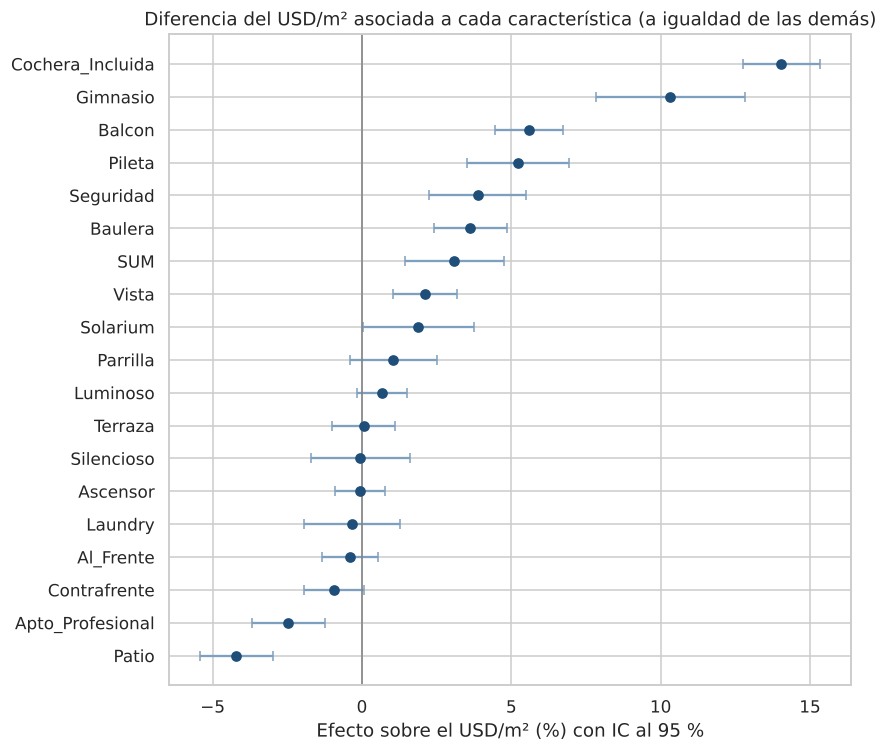

,Efecto (%),IC95 inf.,IC95 sup.,p-valor
Variable,,,,
Cochera_Incluida,14.04,12.76,15.35,0.00
Gimnasio,10.31,7.84,12.84,0.00
Balcon,5.60,4.47,6.74,0.00
Pileta,5.22,3.53,6.93,0.00
Seguridad,3.87,2.26,5.51,0.00
Baulera,3.62,2.40,4.85,0.00
SUM,3.08,1.44,4.76,0.00
Vista,2.10,1.05,3.17,0.00


In [6]:
# 3.3 EFECTO DE LAS CARACTERÍSTICAS (efecto porcentual con IC al 95 %)

carac = efectos.loc[CARACTERISTICAS].sort_values("Efecto (%)")
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(carac))
ax.errorbar(carac["Efecto (%)"], y,
            xerr=[carac["Efecto (%)"] - carac["IC95 inf."], carac["IC95 sup."] - carac["Efecto (%)"]],
            fmt="o", color="#1f4e79", ecolor="#7f9fbf", capsize=3)
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(carac.index)
ax.set(title="Diferencia del USD/m² asociada a cada característica (a igualdad de las demás)",
       xlabel="Efecto sobre el USD/m² (%) con IC al 95 %", ylabel="")
plt.tight_layout()
plt.show()

display(carac.sort_values("Efecto (%)", ascending=False).head(8))

**Conclusión parcial (características).** Las mayores diferencias se asocian con la cochera incluida (+14 %) y el gimnasio (+10 %), seguidas por balcón y pileta (+5 %), seguridad, baulera y SUM (entre +3 % y +4 %) y vista (+2 %). Ascensor, laundry, terraza, luminosidad y silencio no muestran una diferencia distinguible de cero una vez controlada la antigüedad y el resto de las amenities. Es un respaldo cuantitativo a la idea de que la categoría del edificio explica diferencias que el benchmark no captura. Las amenities aparecen asociadas entre sí; la sección 4.1 mide cuánto afecta eso a los coeficientes.

### 4.1. Diagnóstico: colinealidad y residuos

**Colinealidad.** Para las variables de una columna se calcula el factor de
inflación de la varianza (VIF). Para las categóricas con varias columnas
(barrio, ambientes, antigüedad, estado) el VIF de cada dummy no es interpretable,
así que se usa el VIF generalizado (GVIF, Fox y Monette, 1992) y se informa
GVIF^(1/(2·gl)), que es comparable entre términos (para una columna es la raíz
del VIF; preocupa por encima de √5 ≈ 2,2).

**Residuos.** Se revisan los supuestos que importan para leer los coeficientes:
forma de la distribución (asimetría, curtosis, Jarque-Bera), varianza constante
(Breusch-Pagan) y observaciones influyentes (residuos estudentizados y distancia
de Cook).


In [ ]:
# 4.1 COLINEALIDAD (VIF y GVIF por término)

vif = vif_por_termino(modelo.model.exog, modelo.model.exog_names)
display(vif.round(2))


In [ ]:
# 4.2 RESIDUOS

resumen_res, res = diagnostico_residuos(modelo.resid, modelo.fittedvalues, modelo.model.exog)
display(resumen_res.round(4).to_frame("Valor"))

from scipy import stats
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(res["Ajustado"], res["Residuo"], s=4, alpha=.25, color="#1f4e79")
axes[0].axhline(0, color="gray", lw=1)
axes[0].set(title="Residuos vs. valor ajustado", xlabel="log(USD/m²) ajustado", ylabel="Residuo")
(osm, osr), (pend, orig, _) = stats.probplot(res["Residuo_Estudentizado"], dist="norm")
axes[1].scatter(osm, osr, s=4, alpha=.3, color="#1f4e79")
axes[1].plot(osm, pend * osm + orig, color="#C44E52", lw=1)
axes[1].set(title="Gráfico Q-Q de los residuos estudentizados", xlabel="Cuantil normal teórico", ylabel="Cuantil observado")
por_estado = d.loc[res.index].assign(Residuo=res["Residuo"])
sns.boxplot(data=por_estado, x="Residuo", y="Estado", showfliers=False, ax=axes[2], color="#9fb7d1")
axes[2].axvline(0, color="gray", lw=1)
axes[2].set(title="Residuos por estado", xlabel="Residuo (log)", ylabel="")
plt.tight_layout()
plt.show()

print("Avisos más influyentes (mayor distancia de Cook):")
display(d.loc[res.nlargest(5, "Cook").index, ["ID", "Barrio_Oficial", "USD_m2_Homogeneizado", "Estado"]]
        .join(res[["Residuo_Estudentizado", "Leverage", "Cook"]]).round(3))


**Lectura del diagnóstico.**

- **Colinealidad baja en lo que se interpreta.** Las características tienen
  GVIF^(1/(2·gl)) de hasta 1,5 (VIF clásico de hasta 2,2, en SUM, solarium y
  pileta, que suelen aparecer juntas), y el estado, 1,03: sus coeficientes son
  estables. El valor más alto es el de la superficie (VIF ≈ 5), porque está
  asociada con la cantidad de ambientes; afecta la precisión de esos dos
  coeficientes, que se usan como controles y no se interpretan.
- **Residuos simétricos, con colas más pesadas que la normal** (curtosis en
  exceso ≈ 2; Jarque-Bera rechaza). Con más de 9.000 avisos, la inferencia sobre
  los coeficientes no depende de la normalidad, pero conviene leer los intervalos
  de predicción individuales con cautela.
- **Heterocedasticidad.** Breusch-Pagan la detecta, aunque el tamaño de los
  residuos no crece con el valor ajustado: la varianza cambia entre grupos
  (barrios, estados). Por eso el modelo usa errores estándar robustos (HC3).
- **Sin observaciones dominantes.** Alrededor del 1 % de los residuos
  estudentizados supera |3| y la distancia de Cook máxima es muy baja (≈ 0,01):
  ningún aviso mueve por sí solo los coeficientes.


## 5. Validación fuera de muestra

**Pregunta:** ¿predice el modelo el USD/m² de avisos que no usó para estimarse mejor que el benchmark jerárquico?

Se repite cinco veces un holdout 80/20 con semillas distintas. En cada una se compara el error del modelo con el del benchmark jerárquico, sobre los mismos avisos de prueba.

In [7]:
# 4.1 HOLDOUT REPETIDO (5 SEMILLAS)

validacion = validar_fuera_de_muestra(d)
display(validacion)

resumen = pd.DataFrame({"Media": validacion.mean(), "Desvío": validacion.std()}).drop("N prueba")
display(resumen)

,N prueba,MAPE regresión (%),MdAPE regresión (%),MAPE benchmark (%),MdAPE benchmark (%)
Semilla,,,,,
1,1841,15.15,11.39,19.68,14.16
2,1840,15.70,12.32,20.10,15.28
3,1842,15.09,11.65,19.64,14.95
4,1839,15.11,11.36,19.63,15.21
5,1840,15.18,11.69,19.69,15.11


,Media,Desvío
MAPE regresión (%),15.25,0.26
MdAPE regresión (%),11.68,0.39
MAPE benchmark (%),19.75,0.20
MdAPE benchmark (%),14.94,0.46


**Conclusión parcial (validación).** Fuera de muestra, la regresión tiene un error porcentual absoluto medio (MAPE) de alrededor de 15 % y una mediana (MdAPE) de alrededor de 12 %, contra cerca de 20 % y 15 % del benchmark jerárquico. La ventaja se repite en las cinco semillas y el desvío entre ellas es chico (menos de 0,5 puntos). Esto sugiere que incorporar las amenities y las demás características mejora la estimación del valor de referencia, y respalda la prioridad de agregar la categoría del edificio al benchmark. Cabe una precisión: el benchmark calcula su valor con todos los demás avisos, incluidos los del conjunto de prueba, y la regresión solo con el conjunto de entrenamiento; la comparación no favorece a la regresión.

## 6. Conclusiones

- **Estado.** Controlando por ubicación, tamaño, antigüedad y características, `Necesita_obra` se asocia con un USD/m² cerca de 14 % menor que `Buen_estado` y 22 % menor que `Reciclada_refaccionada`. El resultado es estable entre especificaciones. Refuerza H1 con una medición que no confunde el estado con la ubicación o la edad.
- **Amenities.** La cochera, el gimnasio, el balcón, la pileta y la seguridad se asocian con premios de precio de entre 4 % y 14 %. Respaldan incorporar la categoría del edificio al benchmark.
- **Diagnóstico.** La colinealidad entre las variables que se interpretan es baja (VIF ≤ 2,2); los residuos son simétricos pero con colas pesadas y varianza no constante, lo que justifica los errores robustos; ningún aviso es influyente por sí solo.
- **Predicción.** La regresión estima el USD/m² fuera de muestra con menor error que el benchmark jerárquico (MAPE de 15 % contra 20 %).
- **Limitaciones.** Son asociaciones, no causalidad. El estado se infiere del texto y solo está informado en el 36 % de los avisos. Los precios son de publicación, no de cierre. El modelo es lineal en logaritmos y no incluye interacciones, como un premio de amenity distinto según el barrio.
- **Próximo paso.** Incorporar las características al benchmark y evaluar si el PER y la clasificación de oportunidades mejoran, y probar interacciones entre barrio y amenities.